# Questão 14 - Grafos de Conhecimento

## 1. O que é um grafo de conhecimento

Um grafo de conhecimento (Knowledge Graph, KG) guarda fatos sobre o mundo na forma de um grafo. Os nós são entidades (pessoas, filmes, lugares) e as arestas são relações entre elas, cada uma com um nome.

O termo ficou conhecido em 2012, quando o Google passou a usar um grafo desse tipo na busca. É ele que monta o quadro com dados de uma pessoa ou de um filme ao lado dos resultados. Para isso a busca precisa tratar "Christopher Nolan" como uma entidade ligada a outras, e não como duas palavras.

## 2. Representação do conhecimento

A unidade básica é a tripla: sujeito, predicado e objeto. Por exemplo: (A Origem, dirigidoPor, Christopher Nolan). Um KG é um conjunto de triplas.

Há dois modelos principais para guardar essas triplas.

**RDF:** padrão do W3C. Cada entidade e cada relação tem um identificador (IRI). A consulta é feita em SPARQL. Pode ser combinado com RDFS e OWL para descrever classes e regras.

**Grafo de propriedades:** modelo usado pelo Neo4j. Nós e arestas têm rótulos e também podem guardar atributos (pares chave e valor). A consulta é feita em Cypher.

Um KG pode ter um esquema, que diz quais tipos de entidade e de relação existem. O esquema pode ser uma ontologia completa ou só uma lista de tipos. Uma diferença para os bancos relacionais é que o esquema é flexível: dá para acrescentar um tipo novo de relação sem mexer no que já existe.

Neste notebook o grafo é construído em RDF com a biblioteca rdflib. O domínio é um catálogo de filmes, usado depois para recomendação.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from rdflib import Graph, Namespace, RDF

EX = Namespace("http://exemplo.org/filmes#")
kg = Graph()
kg.bind("ex", EX)

# filme: (diretor, gêneros, atores)
filmes = {
    "Matrix": ("Lana_Wachowski", ["Cyberpunk", "Acao"], ["Keanu_Reeves"]),
    "John_Wick": ("Chad_Stahelski", ["Acao"], ["Keanu_Reeves"]),
    "A_Origem": ("Christopher_Nolan", ["FiccaoCientifica", "Suspense"], ["Leonardo_DiCaprio"]),
    "Interestelar": ("Christopher_Nolan", ["FiccaoCientifica", "Drama"], ["Matthew_McConaughey"]),
    "Batman_O_Cavaleiro_das_Trevas": ("Christopher_Nolan", ["Acao", "Suspense"], ["Christian_Bale"]),
    "Blade_Runner": ("Ridley_Scott", ["Cyberpunk"], ["Harrison_Ford"]),
    "Titanic": ("James_Cameron", ["Romance", "Drama"], ["Leonardo_DiCaprio"]),
    "Avatar": ("James_Cameron", ["FiccaoCientifica", "Acao"], ["Zoe_Saldana"]),
    "Ilha_do_Medo": ("Martin_Scorsese", ["Suspense"], ["Leonardo_DiCaprio"]),
    "O_Lobo_de_Wall_Street": ("Martin_Scorsese", ["Drama"], ["Leonardo_DiCaprio", "Matthew_McConaughey"]),
    "Parasita": ("Bong_Joon_ho", ["Suspense", "Drama"], ["Song_Kang_ho"]),
    "Central_do_Brasil": ("Walter_Salles", ["Drama"], ["Fernanda_Montenegro"]),
    "Ainda_Estou_Aqui": ("Walter_Salles", ["Drama"], ["Fernanda_Torres", "Fernanda_Montenegro"]),
    "Cidade_de_Deus": ("Fernando_Meirelles", ["Drama", "Acao"], ["Alexandre_Rodrigues"]),
}

gostos = {
    "Ana": ["Matrix", "A_Origem", "Blade_Runner"],
    "Bruno": ["Titanic", "O_Lobo_de_Wall_Street", "Ilha_do_Medo"],
    "Clara": ["Central_do_Brasil", "Cidade_de_Deus", "Parasita"],
    "Davi": ["Interestelar", "Batman_O_Cavaleiro_das_Trevas", "Matrix", "Avatar"],
    "Elisa": ["Ainda_Estou_Aqui", "Central_do_Brasil", "Titanic"],
    "Fabio": ["John_Wick", "Matrix", "Batman_O_Cavaleiro_das_Trevas"],
    "Gabi": ["A_Origem", "Interestelar", "Ilha_do_Medo", "Parasita"],
    "Hugo": ["Avatar", "Blade_Runner", "Interestelar"],
}

for filme, (diretor, generos, atores) in filmes.items():
    kg.add((EX[filme], RDF.type, EX.Filme))
    kg.add((EX[filme], EX.dirigidoPor, EX[diretor]))
    kg.add((EX[diretor], RDF.type, EX.Pessoa))
    for g in generos:
        kg.add((EX[filme], EX.temGenero, EX[g]))
        kg.add((EX[g], RDF.type, EX.Genero))
    for a in atores:
        kg.add((EX[filme], EX.temAtor, EX[a]))
        kg.add((EX[a], RDF.type, EX.Pessoa))

kg.add((EX.Cyberpunk, EX.subGeneroDe, EX.FiccaoCientifica))
kg.add((EX.FiccaoCientifica, EX.subGeneroDe, EX.Fantastico))
kg.add((EX.Fantastico, RDF.type, EX.Genero))

for usuario, lista in gostos.items():
    kg.add((EX[usuario], RDF.type, EX.Usuario))
    for filme in lista:
        kg.add((EX[usuario], EX.gostou, EX[filme]))

print("Triplas no grafo:", len(kg))

Triplas no grafo: 128


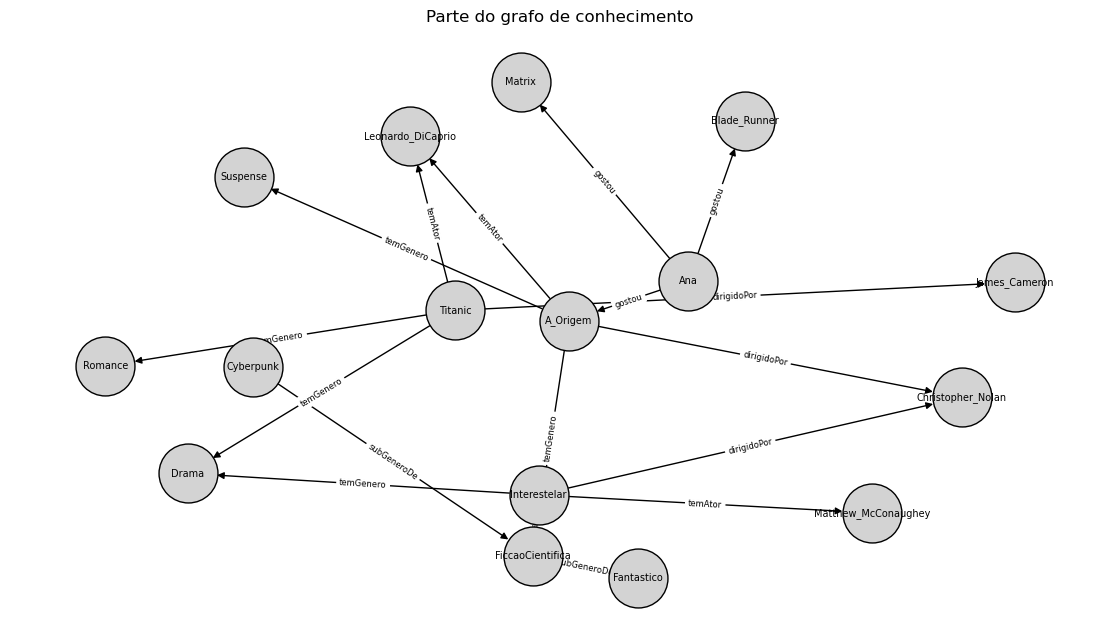

In [2]:
def curto(termo):
    return str(termo).split("#")[-1]


def consultar(sparql, colunas):
    linhas = [[curto(v) for v in linha] for linha in kg.query(sparql, initNs={"ex": EX})]
    return pd.DataFrame(linhas, columns=colunas)


def desenhar(triplas, titulo):
    g = nx.DiGraph()
    for s, p, o in triplas:
        g.add_edge(curto(s), curto(o), rotulo=curto(p))
    pos = nx.spring_layout(g, seed=3, k=1.2)
    plt.figure(figsize=(11, 6))
    nx.draw(g, pos, with_labels=True, node_color="lightgray", node_size=1800, font_size=7, edgecolors="black")
    nx.draw_networkx_edge_labels(g, pos, edge_labels=nx.get_edge_attributes(g, "rotulo"), font_size=6)
    plt.title(titulo)
    plt.show()


vizinhanca = [t for t in kg if curto(t[0]) in ("A_Origem", "Interestelar", "Titanic", "Ana", "Cyberpunk", "FiccaoCientifica") and t[1] != RDF.type]
desenhar(vizinhanca, "Parte do grafo de conhecimento")

A figura mostra só uma parte do grafo. Já dá para ver a ideia principal: os filmes não estão isolados. A Origem e Titanic se ligam pelo ator, A Origem e Interestelar pelo diretor e pelo gênero. São essas ligações que permitem inferir coisas novas.

No Neo4j, a tripla (A Origem, dirigidoPor, Christopher Nolan) seria criada com o comando Cypher abaixo. A ideia é a mesma, muda só a sintaxe.

`CREATE (:Filme {titulo: "A Origem"})-[:DIRIGIDO_POR]->(:Pessoa {nome: "Christopher Nolan"})`

## 3. Inferência

Inferir em um KG é obter fatos que não estão escritos nele. Existem três formas principais.

**Inferência por consulta e caminhos:** seguir as arestas do grafo. Uma resposta que exige passar por duas ou mais arestas já é um fato que não estava guardado diretamente.

**Inferência por regras:** aplicar regras lógicas do tipo "se existem estas triplas, então vale esta outra". É a inferência dedutiva, a mesma dos reasoners de ontologias. As conclusões são certas se as regras e os fatos estiverem certos.

**Inferência por aprendizado:** treinar um modelo que estima a chance de uma tripla ser verdadeira. As conclusões são prováveis e não certas. É o assunto da seção 5.

**Inferência por caminhos**

Pergunta: quais atores já trabalharam com o diretor Christopher Nolan e também com outro diretor? A resposta exige percorrer o caminho diretor, filme, ator, filme, diretor.

In [3]:
consultar(
    """
    SELECT DISTINCT ?ator ?outroDiretor ?filme WHERE {
        ?f1 ex:dirigidoPor ex:Christopher_Nolan ; ex:temAtor ?ator .
        ?filme ex:temAtor ?ator ; ex:dirigidoPor ?outroDiretor .
        FILTER(?outroDiretor != ex:Christopher_Nolan)
    } ORDER BY ?ator ?outroDiretor
    """,
    ["ator", "outro diretor", "filme"],
)

,ator,outro diretor,filme
0,Leonardo_DiCaprio,James_Cameron,Titanic
1,Leonardo_DiCaprio,Martin_Scorsese,Ilha_do_Medo
2,Leonardo_DiCaprio,Martin_Scorsese,O_Lobo_de_Wall_Street
3,Matthew_McConaughey,Martin_Scorsese,O_Lobo_de_Wall_Street


**Inferência por regras**

Cada regra é escrita como uma consulta SPARQL do tipo CONSTRUCT: a parte WHERE é a condição e a parte CONSTRUCT é a conclusão. As regras são aplicadas várias vezes, até não aparecer nenhuma tripla nova. Esse processo é o encadeamento para frente.

Regra 1: se um filme é dirigido por uma pessoa, a pessoa dirigiu o filme (relação inversa).

Regra 2: se A é subgênero de B e B é subgênero de C, então A é subgênero de C (transitividade).

Regra 3: se um filme tem o gênero A e A é subgênero de B, o filme também tem o gênero B (herança).

Regra 4: se dois filmes diferentes têm o mesmo diretor, eles são relacionados.

Regra 5: se um usuário gostou de um filme, ele tem interesse nos gêneros desse filme.

In [4]:
REGRAS = {
    "R1 inversa": "CONSTRUCT { ?d ex:dirigiu ?f } WHERE { ?f ex:dirigidoPor ?d }",
    "R2 transitividade": "CONSTRUCT { ?a ex:subGeneroDe ?c } WHERE { ?a ex:subGeneroDe ?b . ?b ex:subGeneroDe ?c }",
    "R3 herança de gênero": "CONSTRUCT { ?f ex:temGenero ?g2 } WHERE { ?f ex:temGenero ?g . ?g ex:subGeneroDe ?g2 }",
    "R4 mesmo diretor": "CONSTRUCT { ?f1 ex:relacionadoA ?f2 } WHERE { ?f1 ex:dirigidoPor ?d . ?f2 ex:dirigidoPor ?d . FILTER(?f1 != ?f2) }",
    "R5 interesse": "CONSTRUCT { ?u ex:temInteresseEm ?g } WHERE { ?u ex:gostou ?f . ?f ex:temGenero ?g }",
}


def encadear_para_frente(grafo):
    historico, rodada = [], 0
    while True:
        rodada += 1
        # todas as regras olham para o grafo como estava no início da rodada
        novas = {nome: {t for t in grafo.query(regra, initNs={"ex": EX}) if t not in grafo} for nome, regra in REGRAS.items()}
        for nome, triplas_novas in novas.items():
            for t in triplas_novas:
                grafo.add(t)
            historico.append({"rodada": rodada, "regra": nome, "triplas novas": len(triplas_novas)})
        if not any(novas.values()):
            return pd.DataFrame(historico)


antes = len(kg)
historico = encadear_para_frente(kg)
print(f"Triplas antes: {antes} | depois: {len(kg)}")
historico.pivot(index="regra", columns="rodada", values="triplas novas")

Triplas antes: 128 | depois: 195


rodada,1,2,3,4
regra,,,,
R1 inversa,14,0,0,0
R2 transitividade,1,0,0,0
R3 herança de gênero,5,2,0,0
R4 mesmo diretor,12,0,0,0
R5 interesse,27,5,1,0


Na primeira rodada cada regra gera triplas a partir dos fatos originais. Nas rodadas seguintes, as regras usam as triplas criadas antes. Por exemplo, a regra 3 só consegue dar o gênero Fantastico para Matrix depois que a regra 2 concluiu que Cyberpunk é subgênero de Fantastico, e só então a regra 5 conclui que quem gostou de Matrix tem interesse em Fantastico. Quando uma rodada não gera nada, o processo para.

Exemplo de fato inferido: Matrix foi cadastrado só como Cyberpunk e Ação.

In [5]:
consultar("SELECT ?g WHERE { ex:Matrix ex:temGenero ?g } ORDER BY ?g", ["gêneros de Matrix após a inferência"])

,gêneros de Matrix após a inferência
0,Acao
1,Cyberpunk
2,Fantastico
3,FiccaoCientifica


## 4. Aplicação: recomendação de filmes

Sistemas de recomendação são um dos usos mais comuns de KG. Serviços de streaming e lojas virtuais ligam usuários, itens e características dos itens em um grafo. Uma vantagem sobre os métodos que só olham para notas é que o caminho no grafo serve de explicação para a recomendação.

**Como a inferência é feita:** para um usuário, o sistema procura filmes que ele ainda não marcou e que estejam ligados a filmes de que ele gostou. Cada tipo de ligação vale uma pontuação: mesmo diretor vale 3, mesmo ator vale 2 e mesmo gênero vale 1. Os gêneros herdados pela regra 3 também contam. A soma das pontuações ordena os filmes e os caminhos encontrados são mostrados como justificativa.

In [6]:
CAMINHOS = {
    "mesmo diretor": (3, "?visto ex:dirigidoPor ?elo . ?novo ex:dirigidoPor ?elo ."),
    "mesmo ator": (2, "?visto ex:temAtor ?elo . ?novo ex:temAtor ?elo ."),
    "mesmo gênero": (1, "?visto ex:temGenero ?elo . ?novo ex:temGenero ?elo ."),
}


def recomendar(usuario, top=3):
    pontos, motivos = {}, {}
    for tipo, (peso, padrao) in CAMINHOS.items():
        consulta = f"""
            SELECT ?novo ?visto ?elo WHERE {{
                ex:{usuario} ex:gostou ?visto .
                {padrao}
                ?novo a ex:Filme .
                FILTER NOT EXISTS {{ ex:{usuario} ex:gostou ?novo }}
            }}"""
        for novo, visto, elo in kg.query(consulta, initNs={"ex": EX}):
            novo, visto, elo = curto(novo), curto(visto), curto(elo)
            pontos[novo] = pontos.get(novo, 0) + peso
            motivos.setdefault(novo, []).append(f"{tipo} de {visto} ({elo})")
    ordenado = sorted(pontos.items(), key=lambda par: (-par[1], par[0]))[:top]

    print(f"Recomendações para {usuario} (gostou de: {', '.join(gostos[usuario])})")
    for filme, p in ordenado:
        print(f"\n  {filme} | pontuação {p}")
        for m in sorted(motivos[filme]):
            print(f"    {m}")
    return [f for f, _ in ordenado]


_ = recomendar("Ana")

Recomendações para Ana (gostou de: Matrix, A_Origem, Blade_Runner)

  Interestelar | pontuação 9
    mesmo diretor de A_Origem (Christopher_Nolan)
    mesmo gênero de A_Origem (Fantastico)
    mesmo gênero de A_Origem (FiccaoCientifica)
    mesmo gênero de Blade_Runner (Fantastico)
    mesmo gênero de Blade_Runner (FiccaoCientifica)
    mesmo gênero de Matrix (Fantastico)
    mesmo gênero de Matrix (FiccaoCientifica)

  Avatar | pontuação 7
    mesmo gênero de A_Origem (Fantastico)
    mesmo gênero de A_Origem (FiccaoCientifica)
    mesmo gênero de Blade_Runner (Fantastico)
    mesmo gênero de Blade_Runner (FiccaoCientifica)
    mesmo gênero de Matrix (Acao)
    mesmo gênero de Matrix (Fantastico)
    mesmo gênero de Matrix (FiccaoCientifica)

  Batman_O_Cavaleiro_das_Trevas | pontuação 5
    mesmo diretor de A_Origem (Christopher_Nolan)
    mesmo gênero de A_Origem (Suspense)
    mesmo gênero de Matrix (Acao)


In [7]:
_ = recomendar("Elisa")

Recomendações para Elisa (gostou de: Ainda_Estou_Aqui, Central_do_Brasil, Titanic)

  O_Lobo_de_Wall_Street | pontuação 5
    mesmo ator de Titanic (Leonardo_DiCaprio)
    mesmo gênero de Ainda_Estou_Aqui (Drama)
    mesmo gênero de Central_do_Brasil (Drama)
    mesmo gênero de Titanic (Drama)

  Avatar | pontuação 3
    mesmo diretor de Titanic (James_Cameron)

  Cidade_de_Deus | pontuação 3
    mesmo gênero de Ainda_Estou_Aqui (Drama)
    mesmo gênero de Central_do_Brasil (Drama)
    mesmo gênero de Titanic (Drama)


Para Ana, que gostou de Matrix, A Origem e Blade Runner, o sistema indica filmes de Christopher Nolan e de ficção científica. Para Elisa, indica dramas e filmes com os mesmos atores. Em cada caso a explicação é o próprio caminho no grafo.

## 5. Aprendizagem em grafos de conhecimento

Todo KG é incompleto. A aprendizagem é usada principalmente para completar o grafo, ou seja, prever ligações que faltam. A técnica mais comum é a de embeddings: cada entidade e cada relação vira um vetor de números, e esses vetores são ajustados para que as triplas verdadeiras tenham pontuação melhor que as falsas.

O modelo mais simples é o TransE. Ele trata a relação como um deslocamento: se a tripla (h, r, t) é verdadeira, o vetor de h somado ao vetor de r deve ficar perto do vetor de t. A pontuação de uma tripla é a distância entre h + r e t. Quanto menor, mais plausível.

O treino usa exemplos negativos. Para cada tripla verdadeira é criada uma falsa, trocando o sujeito ou o objeto por uma entidade sorteada. O modelo é ajustado para que a distância da verdadeira seja menor que a da falsa por uma margem.

Abaixo o TransE é implementado com numpy e treinado nas triplas originais do grafo. Antes do treino, seis triplas do tipo gostou são escondidas para servir de teste.

In [8]:
escondidas = [("Davi", "Interestelar"), ("Clara", "Cidade_de_Deus"), ("Fabio", "Batman_O_Cavaleiro_das_Trevas"),
              ("Hugo", "Blade_Runner"), ("Gabi", "A_Origem"), ("Elisa", "Central_do_Brasil")]
gostos_treino = {u: [f for f in fs if (u, f) not in escondidas] for u, fs in gostos.items()}

triplas = []
for filme, (diretor, generos, atores) in filmes.items():
    triplas.append((filme, "dirigidoPor", diretor))
    triplas += [(filme, "temGenero", g) for g in generos]
    triplas += [(filme, "temAtor", a) for a in atores]
triplas += [("Cyberpunk", "subGeneroDe", "FiccaoCientifica"), ("FiccaoCientifica", "subGeneroDe", "Fantastico")]
triplas += [(u, "gostou", f) for u, fs in gostos_treino.items() for f in fs]

entidades = sorted({x for h, _, t in triplas for x in (h, t)})
relacoes = sorted({r for _, r, _ in triplas})
ie = {e: i for i, e in enumerate(entidades)}
ir = {r: i for i, r in enumerate(relacoes)}
dados = np.array([(ie[h], ir[r], ie[t]) for h, r, t in triplas])
print(len(entidades), "entidades,", len(relacoes), "relações,", len(triplas), "triplas de treino")

48 entidades, 5 relações, 74 triplas de treino


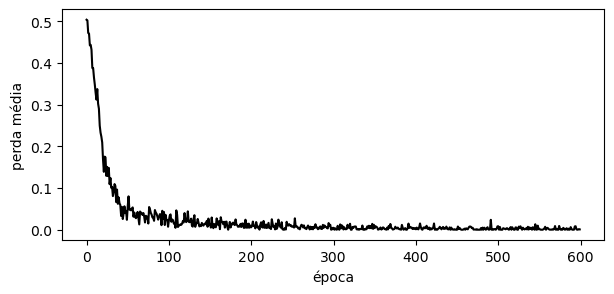

In [9]:
def treinar_transe(dados, n_ent, n_rel, dim=8, margem=0.5, taxa=0.01, epocas=600, seed=0):
    rng = np.random.default_rng(seed)
    E = rng.normal(0, 0.1, (n_ent, dim))
    R = rng.normal(0, 0.1, (n_rel, dim))
    verdadeiras = {tuple(t) for t in dados}
    perdas = []
    for _ in range(epocas):
        E /= np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1)
        total = 0.0
        for h, r, t in rng.permutation(dados):
            # exemplo negativo: troca o sujeito ou o objeto
            hn, tn = h, t
            while (hn, r, tn) in verdadeiras:
                if rng.random() < 0.5:
                    hn = rng.integers(n_ent)
                else:
                    tn = rng.integers(n_ent)
            d_pos = E[h] + R[r] - E[t]
            d_neg = E[hn] + R[r] - E[tn]
            perda = margem + d_pos @ d_pos - d_neg @ d_neg
            if perda > 0:
                total += perda
                E[h] -= taxa * 2 * d_pos
                E[t] += taxa * 2 * d_pos
                E[hn] += taxa * 2 * d_neg
                E[tn] -= taxa * 2 * d_neg
                R[r] -= taxa * 2 * (d_pos - d_neg)
        perdas.append(total / len(dados))
    return E, R, perdas


E, R, perdas = treinar_transe(dados, len(entidades), len(relacoes))

plt.figure(figsize=(7, 3))
plt.plot(perdas, color="black")
plt.xlabel("época")
plt.ylabel("perda média")
plt.show()

**Previsão de ligações**

Para prever de quais filmes um usuário vai gostar, calcula-se a distância entre (usuário + gostou) e cada filme que ele ainda não marcou. Os filmes mais próximos são os mais prováveis.

A tabela mostra em que posição ficou cada filme escondido. Posição 1 significa que o modelo colocou o filme certo em primeiro lugar.

In [10]:
def prever(usuario, top=None):
    vistos = set(gostos_treino[usuario])
    candidatos = [f for f in filmes if f not in vistos]
    dist = [np.linalg.norm(E[ie[usuario]] + R[ir["gostou"]] - E[ie[f]]) for f in candidatos]
    ordem = np.argsort(dist)
    return [(candidatos[i], round(float(dist[i]), 3)) for i in ordem][:top]


linhas = []
for usuario, filme in escondidas:
    ranking = [f for f, _ in prever(usuario)]
    linhas.append({"usuário": usuario, "filme escondido": filme, "posição": ranking.index(filme) + 1,
                   "candidatos": len(ranking), "3 primeiros": ", ".join(ranking[:3])})
resultado = pd.DataFrame(linhas)
print(f"Posição média: {resultado['posição'].mean():.1f} | esperada ao acaso: {(resultado['candidatos'].mean() + 1) / 2:.1f}")
resultado

Posição média: 3.8 | esperada ao acaso: 6.3


,usuário,filme escondido,posição,candidatos,3 primeiros
0,Davi,Interestelar,4,11,"John_Wick, A_Origem, Blade_Runner"
1,Clara,Cidade_de_Deus,4,12,"Titanic, Ainda_Estou_Aqui, Ilha_do_Medo"
2,Fabio,Batman_O_Cavaleiro_das_Trevas,2,12,"Avatar, Batman_O_Cavaleiro_das_Trevas, Ainda_E..."
3,Hugo,Blade_Runner,10,12,"Parasita, Titanic, A_Origem"
4,Gabi,A_Origem,2,11,"O_Lobo_de_Wall_Street, A_Origem, Titanic"
5,Elisa,Central_do_Brasil,1,12,"Central_do_Brasil, O_Lobo_de_Wall_Street, Matrix"


O modelo não viu essas triplas no treino. Na média ele coloca os filmes escondidos em posição melhor do que um sorteio colocaria, e acerta bem em alguns casos. Isso foi aprendido só a partir da forma do grafo: usuários com gostos parecidos e filmes com diretor, ator ou gênero em comum ficam com vetores próximos.

O resultado não é bom em todos os casos. O grafo é muito pequeno: cada usuário tem dois ou três filmes no treino, o que é pouco para o modelo aprender o gosto dele. Por isso as posições mudam com a semente e com os filmes escondidos. Em grafos reais, com milhões de triplas, o padrão fica mais estável.

**Vetores aprendidos**

Projetando os vetores dos filmes em duas dimensões (PCA), filmes parecidos ficam próximos.

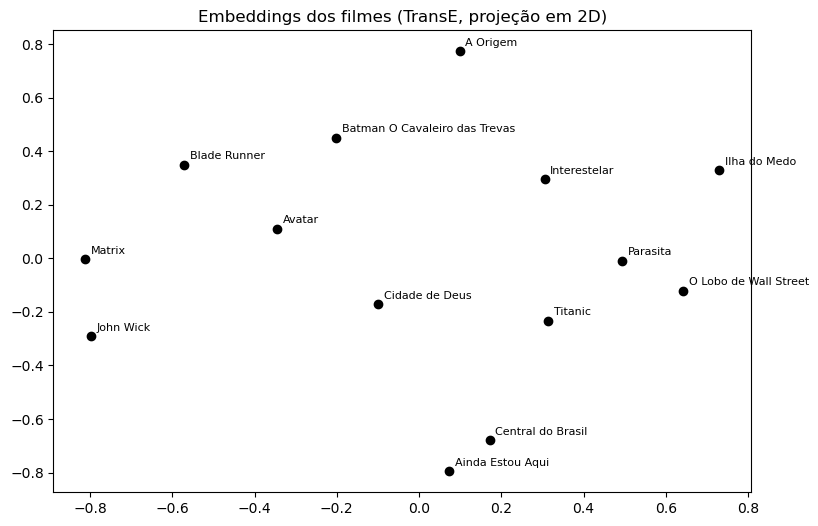

In [11]:
nomes_filmes = list(filmes)
X = E[[ie[f] for f in nomes_filmes]]
X = X - X.mean(axis=0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)
P = X @ Vt[:2].T

plt.figure(figsize=(9, 6))
plt.scatter(P[:, 0], P[:, 1], color="black")
for nome, (x, y) in zip(nomes_filmes, P):
    plt.annotate(nome.replace("_", " "), (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.title("Embeddings dos filmes (TransE, projeção em 2D)")
plt.show()

## 6. Comparação entre as duas formas de inferência

A inferência por regras e caminhos é exata e explicável: cada recomendação vem com o caminho que a justifica. Em compensação, só encontra o que as regras escritas permitem.

A inferência por embeddings descobre padrões que ninguém escreveu e funciona mesmo com o grafo incompleto. Em compensação, o resultado é uma estimativa, pode errar e é difícil de explicar, porque a resposta sai de uma conta com vetores.

Na prática as duas são usadas juntas: os embeddings sugerem ligações novas e as regras e o esquema servem para validar e explicar.

## 7. Referências

BORDES, Antoine et al. Translating embeddings for modeling multi-relational data. In: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS, 26., 2013, Lake Tahoe. Proceedings [...]. Red Hook: Curran Associates, 2013. p. 2787-2795.

HOGAN, Aidan et al. Knowledge graphs. ACM Computing Surveys, New York, v. 54, n. 4, p. 1-37, 2021.

SINGHAL, Amit. Introducing the Knowledge Graph: things, not strings. Google, 16 maio 2012. Disponível em: https://blog.google/products/search/introducing-knowledge-graph-things-not/. Acesso em: 11 nov. 2026.